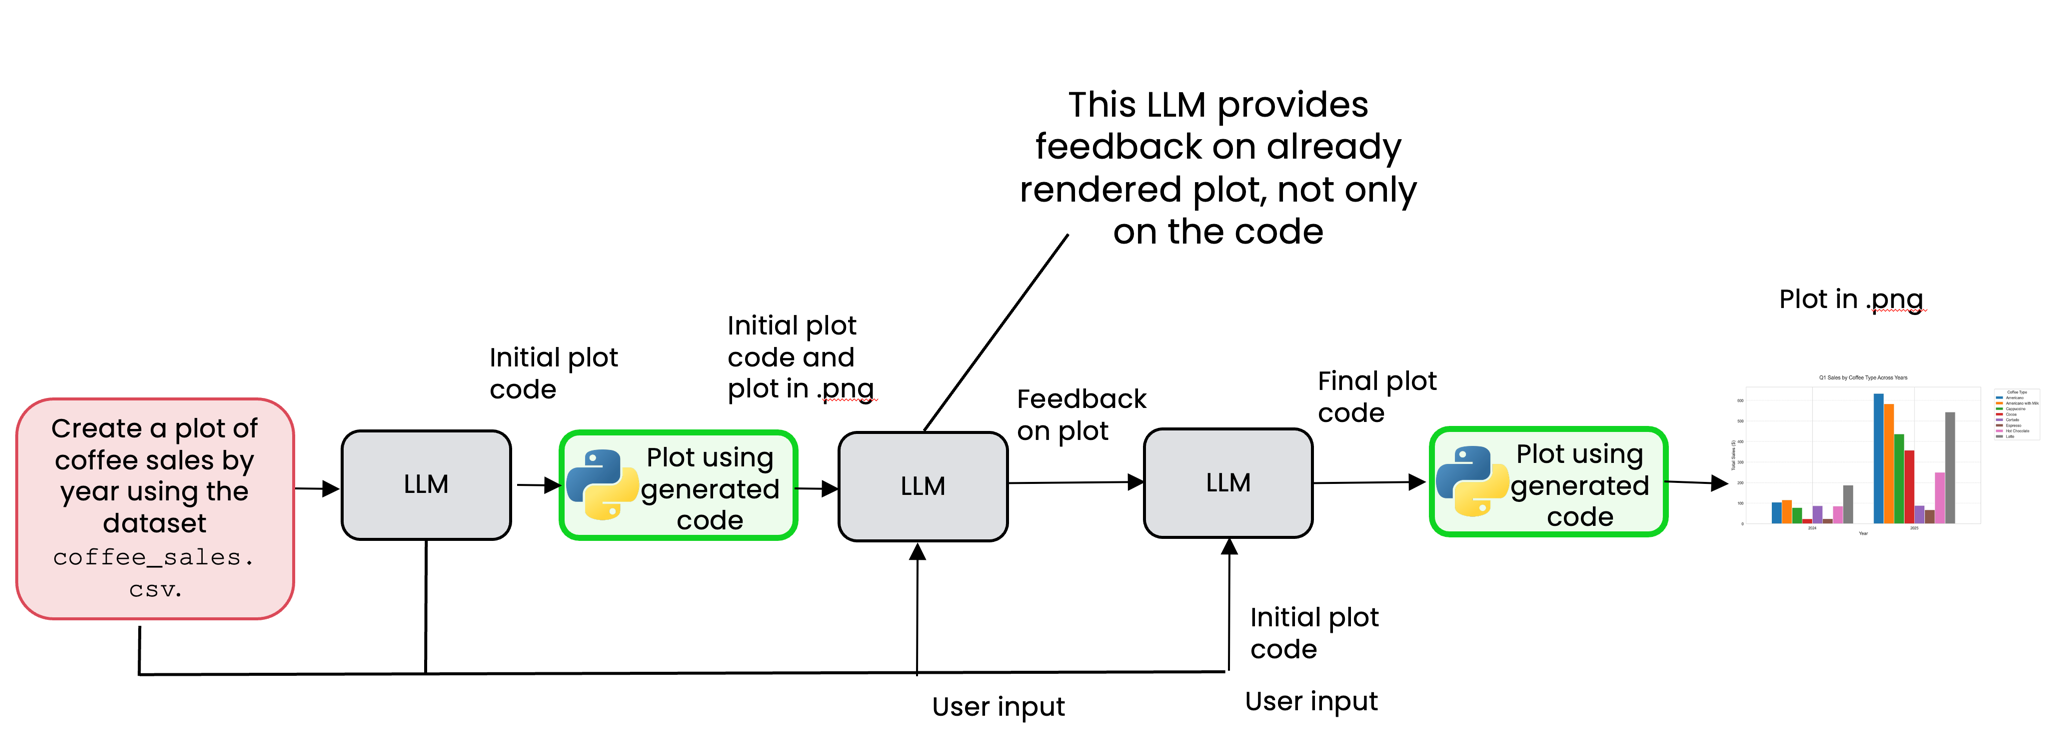

In [45]:
import json
import re

import utils


**CARICAMENTO DEL DATASET**

In [46]:
df = utils.load_and_prepare_data(csv_path="coffee_sales.csv")

print(df.sample())

           date   time cash_type                 card  price coffee_name  \
1860 2024-10-10  06:05      card  ANON-0000-0000-0003  2.596   Americano   

      quarter  month  year  
1860        4     10  2024  


In [47]:

def generate_chart_code(instruction: str, model: str, out_path_v1: str) -> str:
    """Genera codice python per il plotting con matplotlib usando wrapping
    tag-based per render disponibile l'estrazione del codice"""

    prompt = f"""
    You are a data visualization expert
    
    Return your answer strictly in this format:
    
    <execute_python>
    # valid python code
    </execute_python>
    
    Do not add explaination, only the tags and the code.
    
    The code should create a visualization from a DataFrame 'df' with this columns:
    - date (Y-M-D)
    - time (HH:MM)
    - cash_type (card or cash)
    - card (string)
    - price (number)
    - coffee_name (string)
    - quarter (1-4)
    - month (1-12)
    - year (YYYY)
    
    User instruction: {instruction}
    
    Requirements for the code:
    1. Assume DataFrame si already loaded as 'df'
    2. Use matplotlib for plotting
    3. Add clear title, axis, lable, and legend if needed
    4. Save the figure as '{out_path_v1}' with dpi=300
    5. Do not call plt.show()
    6. Close all plotes with plt.close()
    7. Add all necessary import statement
    
    Return ONLY the code wrapped in <execute_python> tags
    """

    response = utils.get_response(model, prompt=prompt)
    return response

code_v1 = generate_chart_code(
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv.",
    out_path_v1="chart_v1.png", 
    model= "gemini-3.5-flash-lite",
)

print(code_v1)

<execute_python>
import matplotlib.pyplot as plt
import pandas as pd

# Filter for Q1 (months 1, 2, 3) and years 2024 and 2025
q1_df = df[(df['quarter'] == 1) & (df['year'].isin([2024, 2025]))]

# Group by year and month to get total sales (price)
sales_comparison = q1_df.groupby(['year', 'month'])['price'].sum().unstack(level=0)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

sales_comparison.plot(kind='bar', ax=ax, width=0.8, color=['#4C72B0', '#55A868'])

ax.set_title('Q1 Coffee Sales Comparison: 2024 vs 2025', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Total Sales ($)', fontsize=12)
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['January', 'February', 'March'], rotation=0)
ax.legend(['2024', '2025'], title='Year', fontsize=10, title_fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('chart_v1.png', dpi=300)
plt.close()
</execute_python>


In [48]:
"""
1. Estrai il codice tramite regex (wrapped in <execute_python>)
2. Esegu il codice in un ambiente comune al DataFrame df
3. Visualizza il chart in .html
"""

'\n1. Estrai il codice tramite regex (wrapped in <execute_python>)\n2. Esegu il codice in un ambiente comune al DataFrame df\n3. Visualizza il chart in .html\n'


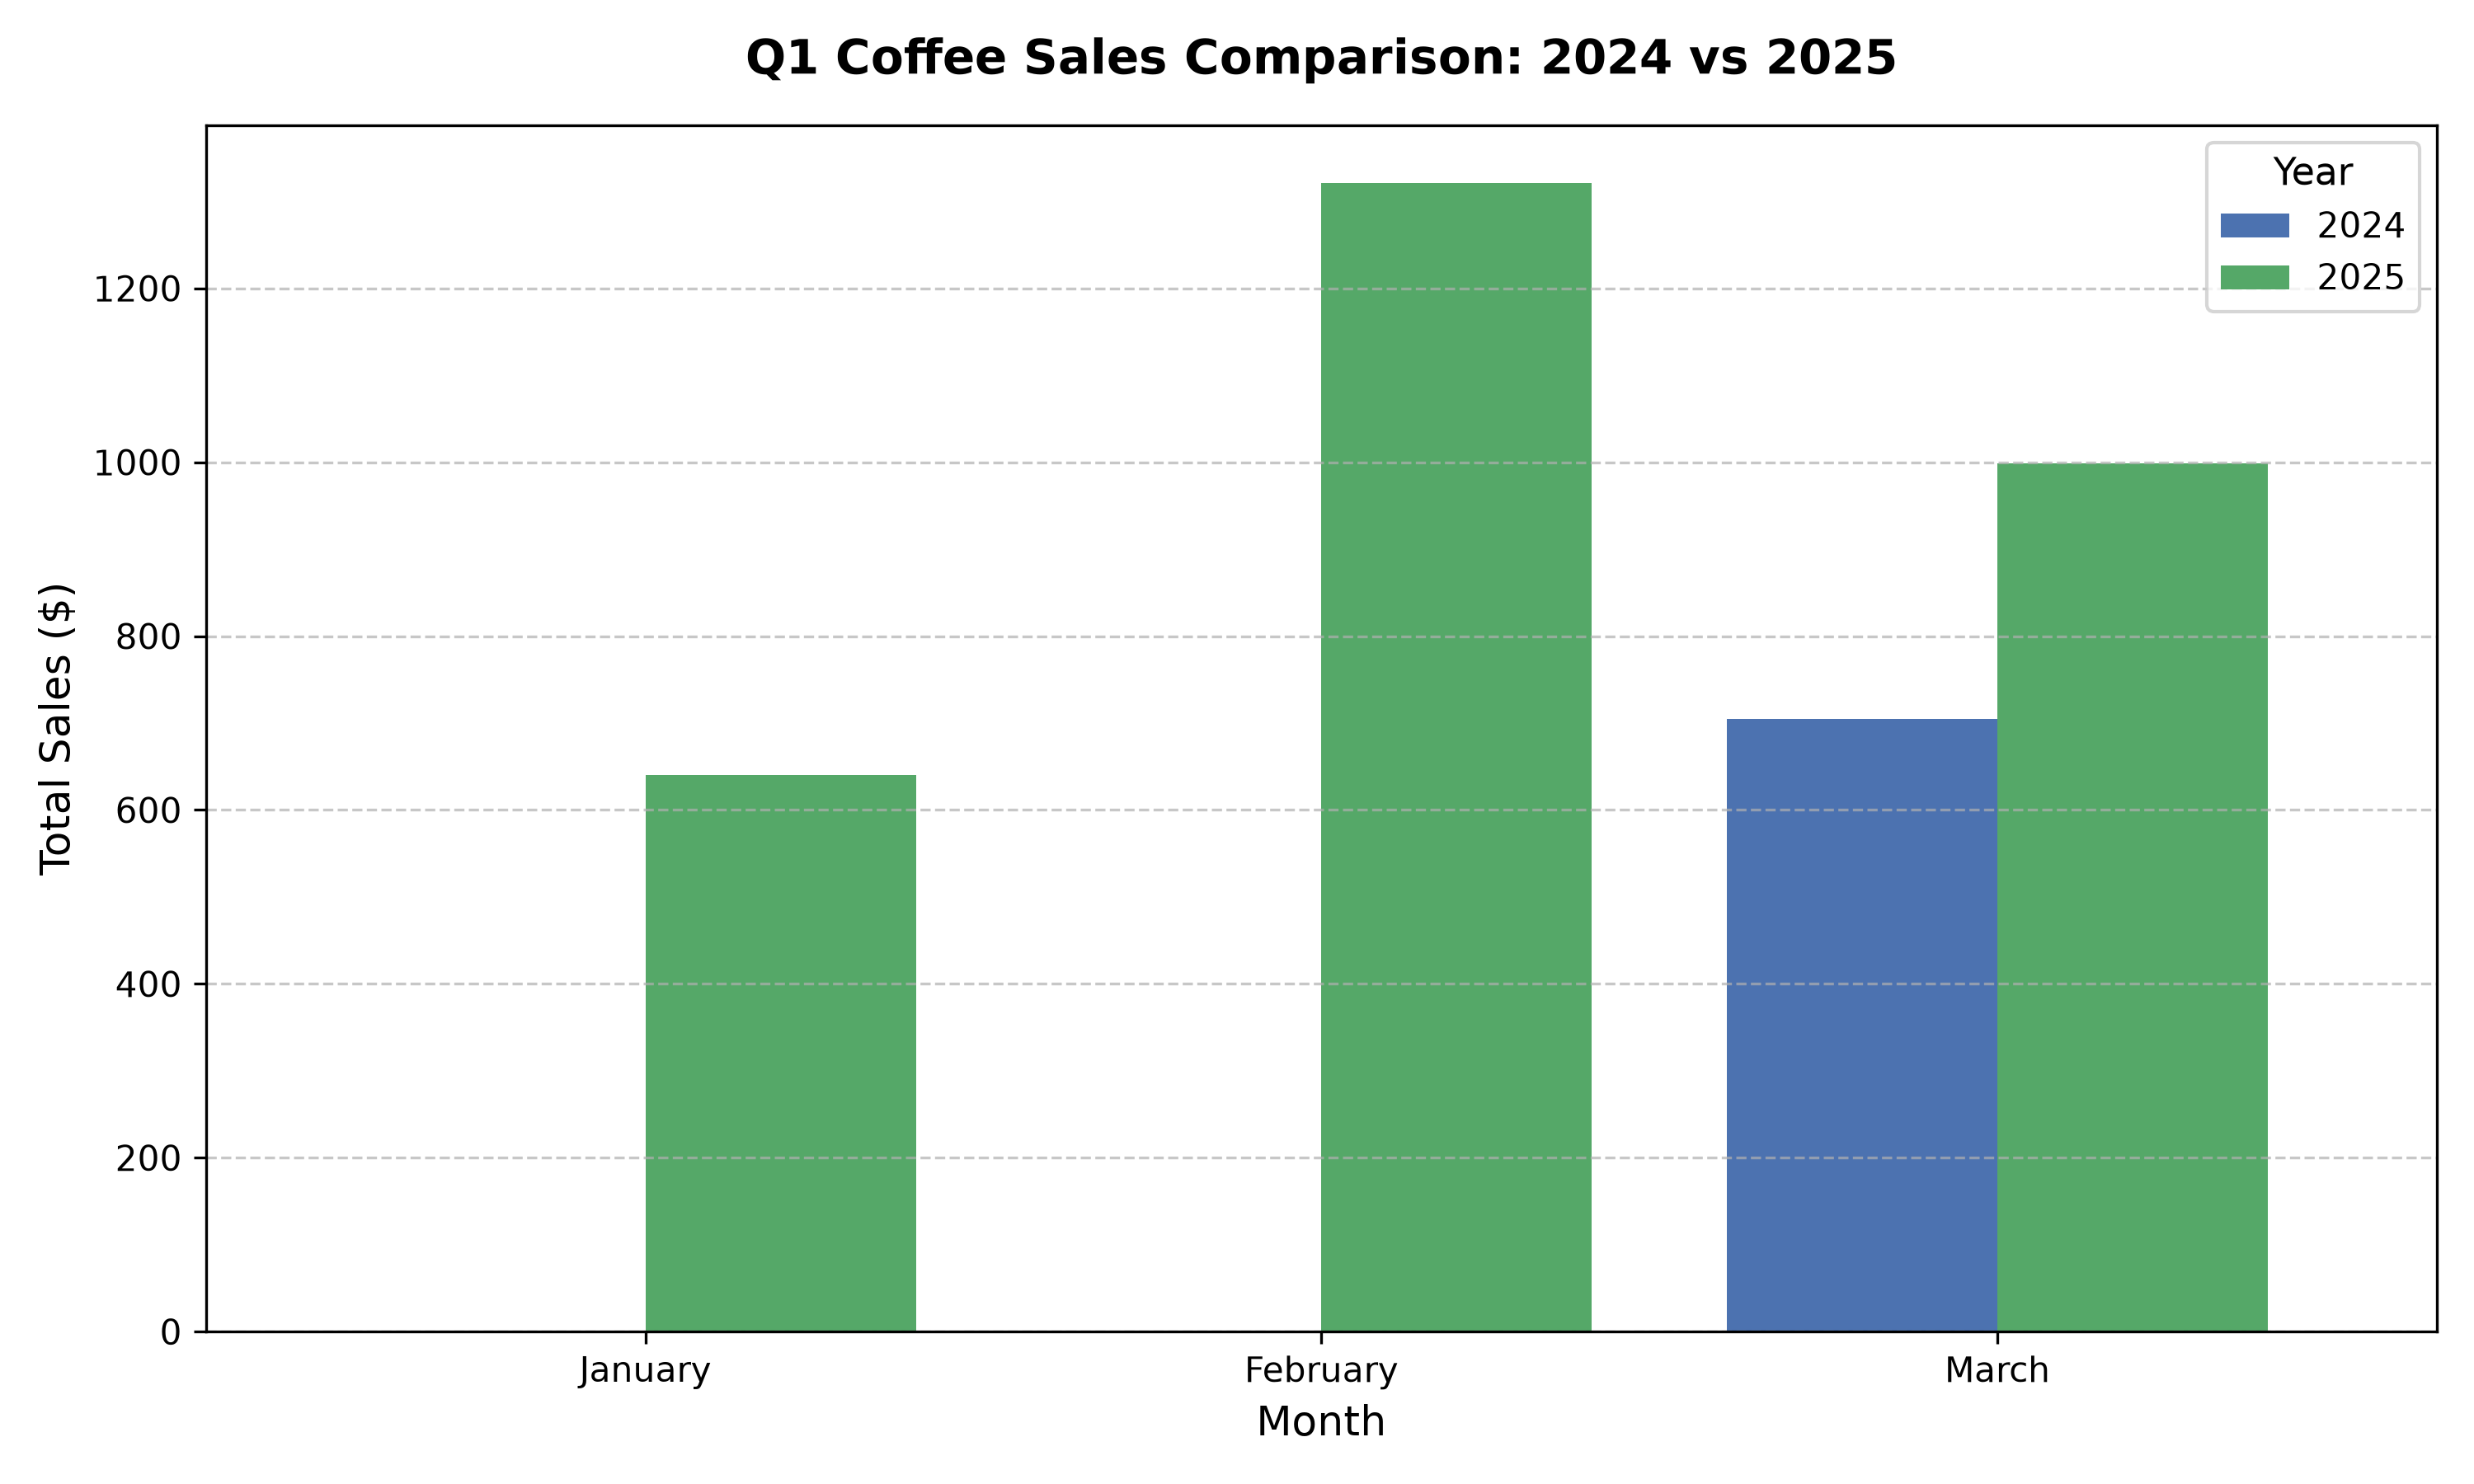

In [49]:
match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
if match:
    initial_code = match.group(1).strip()       # all'interno di raw: (...) gruppo di cattura che si recupera con group(1)
    utils.print_html(initial_code, title="Extracted Code to Execute")
    exec_globals = {"df": df}
    exec(initial_code, globals=exec_globals)

# if code run successfully
utils.print_html(content="chart_v1.png", title="Generated Chart (v1)", is_image=True)

**REFLECT ON THE OUTPUT**
L'obbiettivo e' simulare come un umano ricontrollerebbe una prima bozza di un grafico:
1. Fornisci il chart all'LLM
2. Analizza visivamente il chart
3. Genera un feeback
In questo modo si produce un feedback loop intelligente che critica attivamente il grafico prodotto, preparando le basi per una seconda versione.

In [50]:
def reflect_on_image_and_regenerate(
    chart_path: str,
    instruction: str,
    model_name: str,
    out_path_v2: str,
    code_v1: str,
    ) -> tuple[str, str]:

    """
        Critica l'IMAGE del chart e il codice originale contro le instruzioni, 
        successivamente restituisce una seconda versione del codice di plotting.
        Returns (feedback, refined_code_with_tags)
        Supports OpenAI and Anthropic
    """
    
    media_type, b64 = utils.encode_image_b64(chart_path)
    
    prompt = f"""
        You are a data visualization expert. 
        Your task: critique the attached chart and the original code against the given instructions, 
        then return improved matplolib code.
        
        Original code (for context): 
        {code_v1}
        
        OUTPUT FORMAT (STRICT):
        1)A valid json object with ONLY the "feedback" field.
         Example: {{"feedback": "The legend is unclear and the axis labels overlap."}}
        
        2)After a newline, output ONLY the refined Python code wrapped in:
        <execute_python>
        ...
        </execute_python>
        
        3)Import all necessary libraries in the code. Don't assume any imports from the original code.
        
        HARD CONSTRAINTS:
        - Do NOT include Markdown, backticks, or any extra prose outside the two parts above.
        - Use pandas/matplotlib only (no seaborn)
        - Assume df already exists; do not read from files
        - Save to '{out_path_v2}' with dpi=300
        - Always call plt.close() at the end (no plt.show())
        - Include all necessary import statements
        
        Schema (columns available in df):
            - date (Y-M-D)
            - time (HH:MM)
            - cash_type (card or cash)
            - card (string)
            - price (number)
            - coffee_name (string)
            - quarter (1-4)
            - month (1-12)
            - year (YYYY)
        
        Instruction:
        {instruction}
    """
    
    lower = model_name.lower()
    if "claude" in lower or "anthropic" in lower:
        content = utils.image_anthropic_call(model_name, prompt, media_type, b64)
    else: 
        content = utils.image_openai_call(model_name, prompt, media_type, b64)
    
    # -- Parse only the first JSON line (feeback) --
    lines = content.strip().splitlines()
    json_line = lines[0].strip() if lines else ""
    
    try:
        obj = json.loads(json_line)
    except Exception as e:
        # fallback: try to capture the first {...} in all the content
        m_json = re.search(r"\{.*?\}", content, flags=re.DOTALL)
        if m_json:
            try:
                obj = json.loads(m_json.group(0))
            except Exception as e2:
                obj = {"feedback": f"failed to parse JSON: {e2}", "refined_code": ""}
        else:
            obj = {"feedback": f"failed to parse JSON: {e}", "refined_code": ""}
    
    # -- Extract refined code from <execute_python>...</execute_python> --
    m_code = re.search(r"<execute_python>([\s\S]*?)</execute_python>", content, flags=re.DOTALL)
    refined_code_body = m_code.group(1).strip() if m_code else ""
    refined_code = utils.ensure_execute_python_tags(refined_code_body)
    
    feedback = str(obj.get("feedback", "")).strip()
    return feedback, refined_code


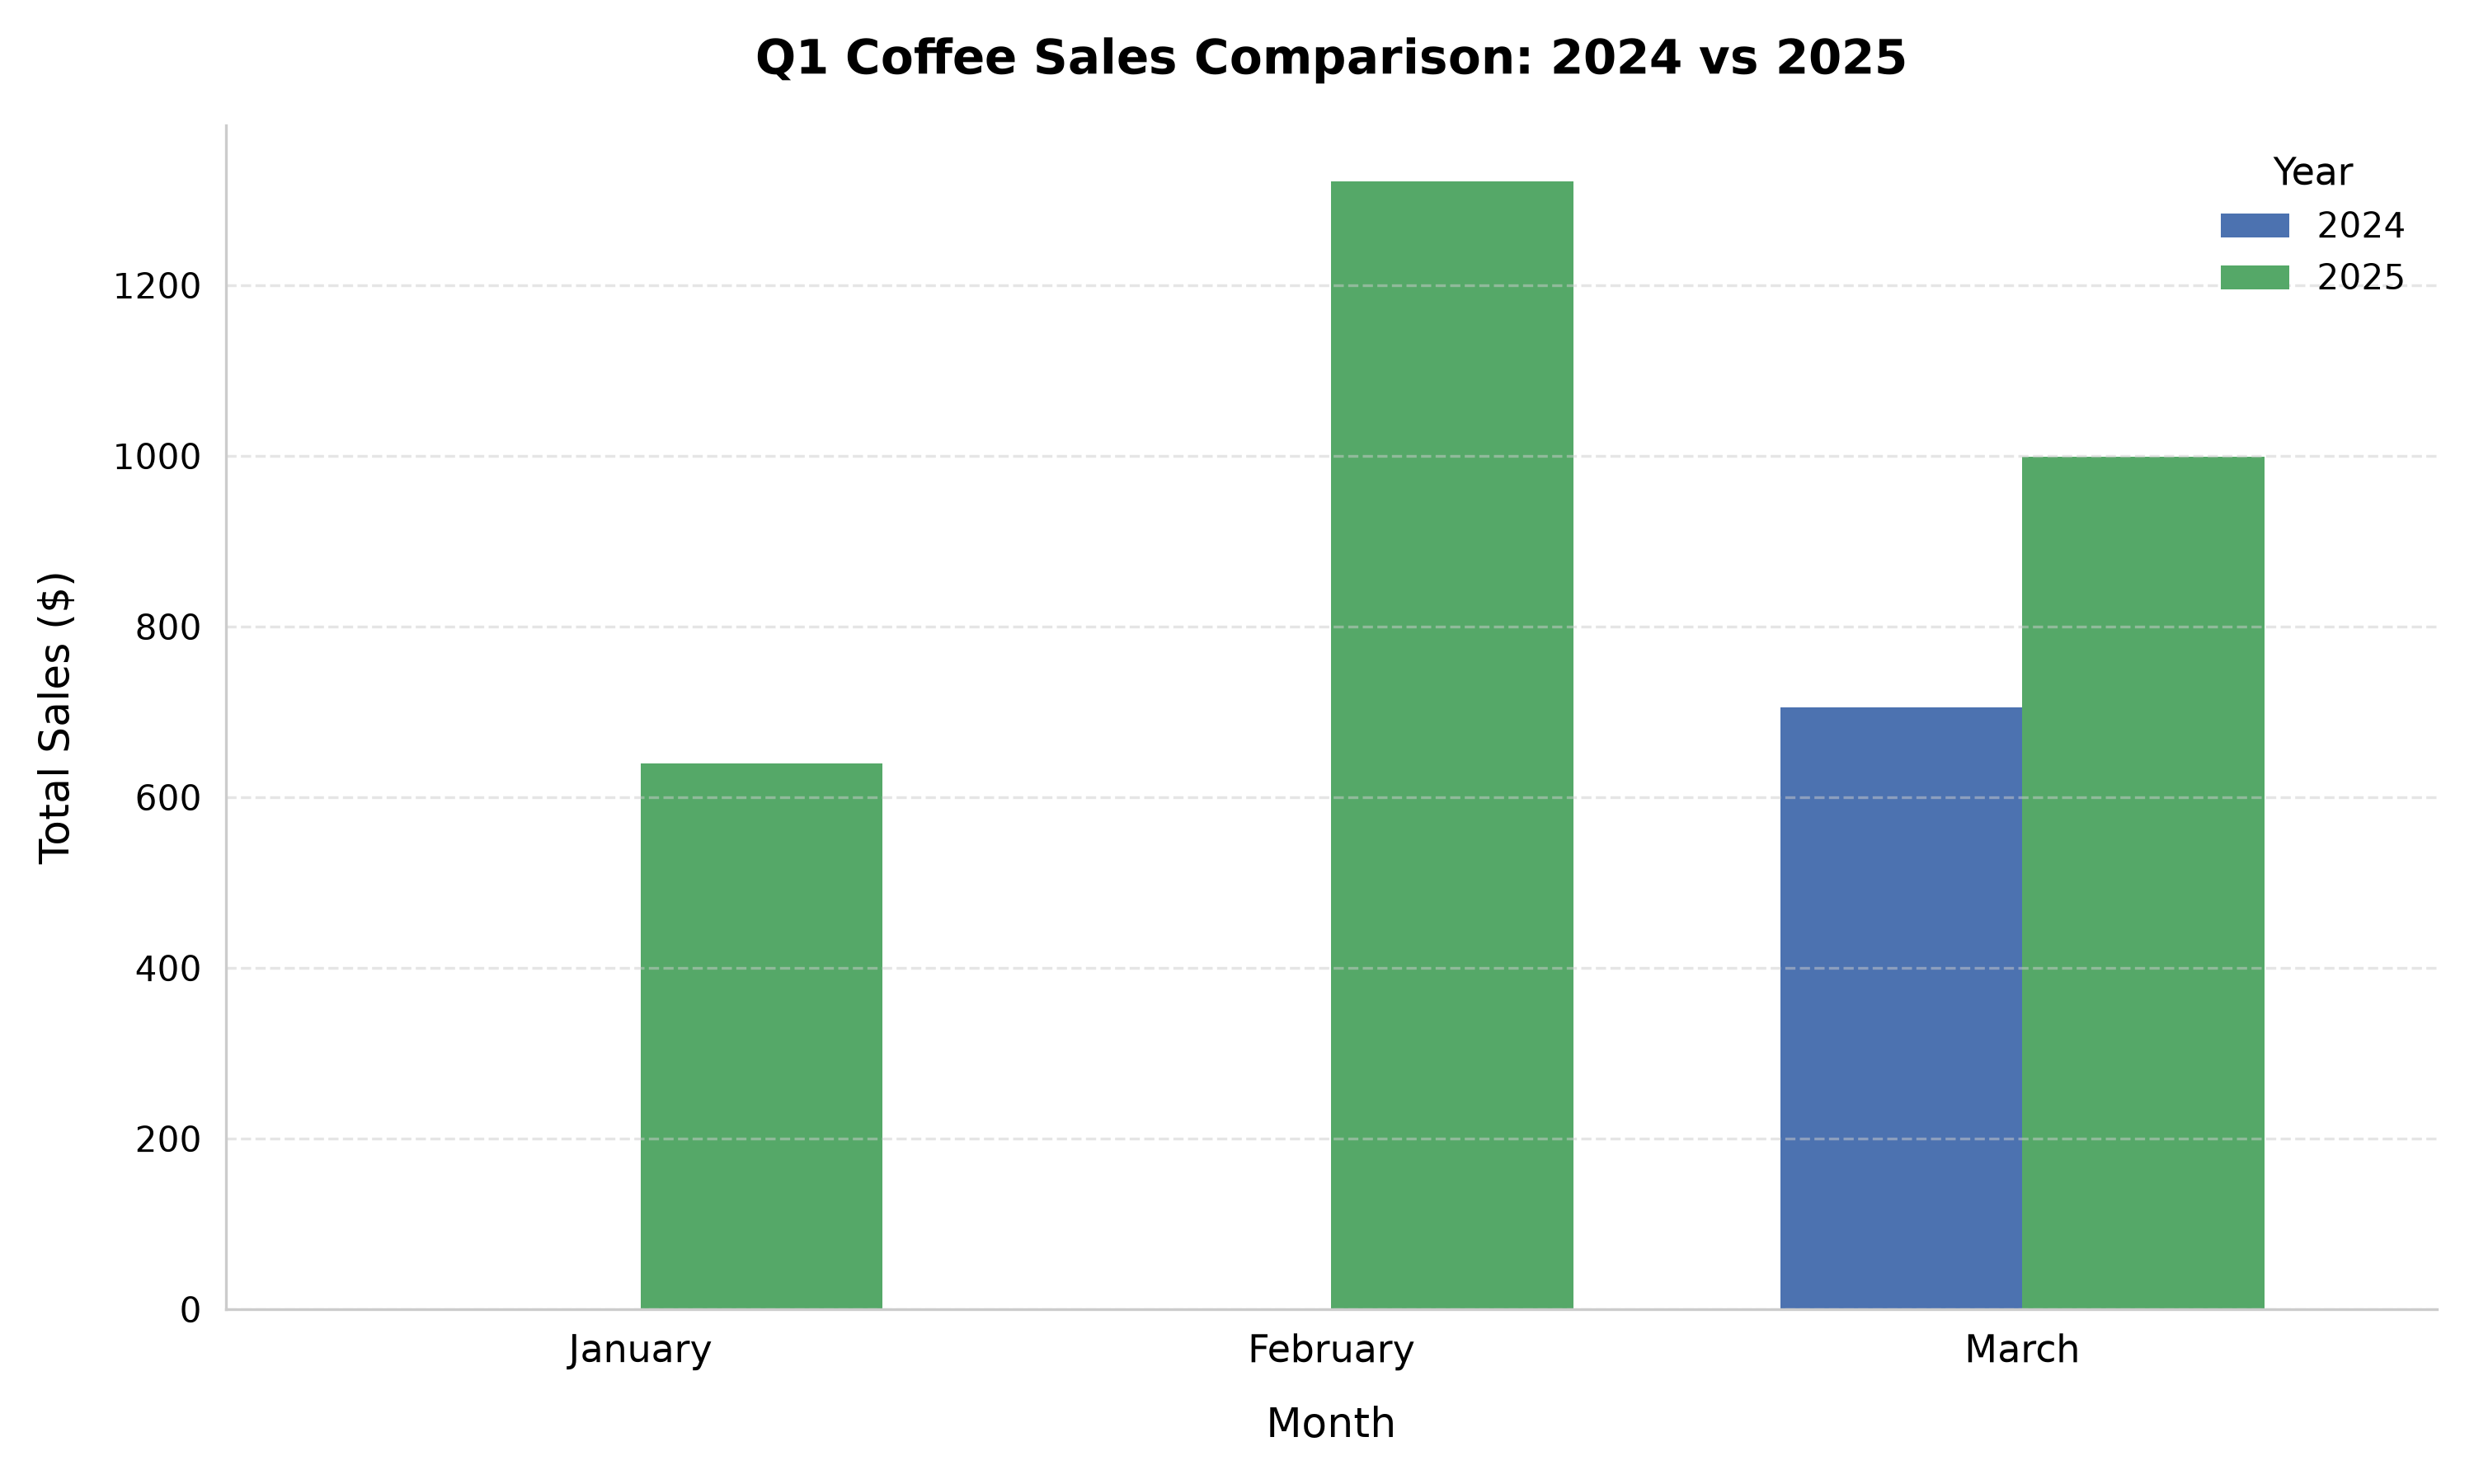

In [51]:
feedback, code_v2 = reflect_on_image_and_regenerate(
    chart_path="chart_v1.png",
    model_name="gemini-3.5-flash-lite",
    out_path_v2="chart_v2.png",
    code_v1=code_v1,
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv",
)

utils.print_html(code_v2, title="Extracted Code to Execute")

match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2, re.DOTALL)
refined_code = match.group(1).strip() if match else ""
exec_globals = {"df": df}
exec(refined_code, globals=exec_globals)

utils.print_html(content="chart_v2.png", is_image=True, title="Generated chart(v2)")


In [53]:
def run_workflow(
    dataset_path: str, 
    user_instruction: str, 
    generation_model: str, 
    reflection_model: str, 
    image_baseline: str = "chart"
):
    """
    End-to-End pipeline: 
        1) load dataset
        2) generate V1 code
        3) execute V1 -> produce chart_v1.png
        4) reflect on V1 (image + original code) -> feedback + refined code V2
        5) execute V2 -> produce chart_v2.png
    
    Returns a dict with all artifacts (codes, feedback, image paths)
    """
    # 1) load dataset; utils handles parsing 
    df = utils.load_and_prepare_data(dataset_path)
    utils.print_html(df.sample(n=1), title="Random sample from DataFrame")
    
    # -- paths to store charts
    out_path_v1 = f"{image_baseline}_v1.png"
    out_path_v2 = f"{image_baseline}_v2.png"
    
    # 2) generate code (v1)
    utils.print_html("Step1: Generating chart code (V1)")
    code_v1 = generate_chart_code(
        instruction=user_instruction, 
        model=generation_model, 
        out_path_v1=out_path_v1
    )
    utils.print_html(code_v1, title="LLM output with first draft code (V1)")
    
    # 3) execute V1 (hard-coded: extract <execute_python> block and run)
    utils.print_html("Step2: Executing chart code (V1)")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
    if match:
        initial_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(initial_code, globals=exec_globals)
    utils.print_html("chart_v1.png", title="Generated Chart (V1)", is_image=True)
    
    # 4) reflect on V1 (image + original code) to get feedback and refined code
    utils.print_html("Step3: reflecting on generated image and initial code")
    feedback, code_v2 = reflect_on_image_and_regenerate("chart_v1.png", 
                                                        instruction=user_instruction, 
                                                        model_name=reflection_model,
                                                        out_path_v2=out_path_v2,
                                                        code_v1=code_v1)
    utils.print_html(feedback, title="Reflection feedback on V1")
    utils.print_html(code_v2, title="LLM output with revised code (V2)")
    
    # 5) execute V2 (hard-coded)
    utils.print_html("Step4: executing chart code (V2)")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2)
    if match:
        refined_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(refined_code, globals=exec_globals)
    utils.print_html("chart_v2.png", title="Regenerated Chart (V2)", is_image=True)
    
    return {
        "code_v1": code_v1, 
        "chart_v1": out_path_v1,
        "feedback": feedback,
        "code_v2": code_v2,
        "chart_v2": out_path_v2
    }

date,time,cash_type,card,price,coffee_name,quarter,month,year
2024-06-30,16:20,card,ANON-0000-0000-0097,3.282,Americano with Milk,2,6,2024



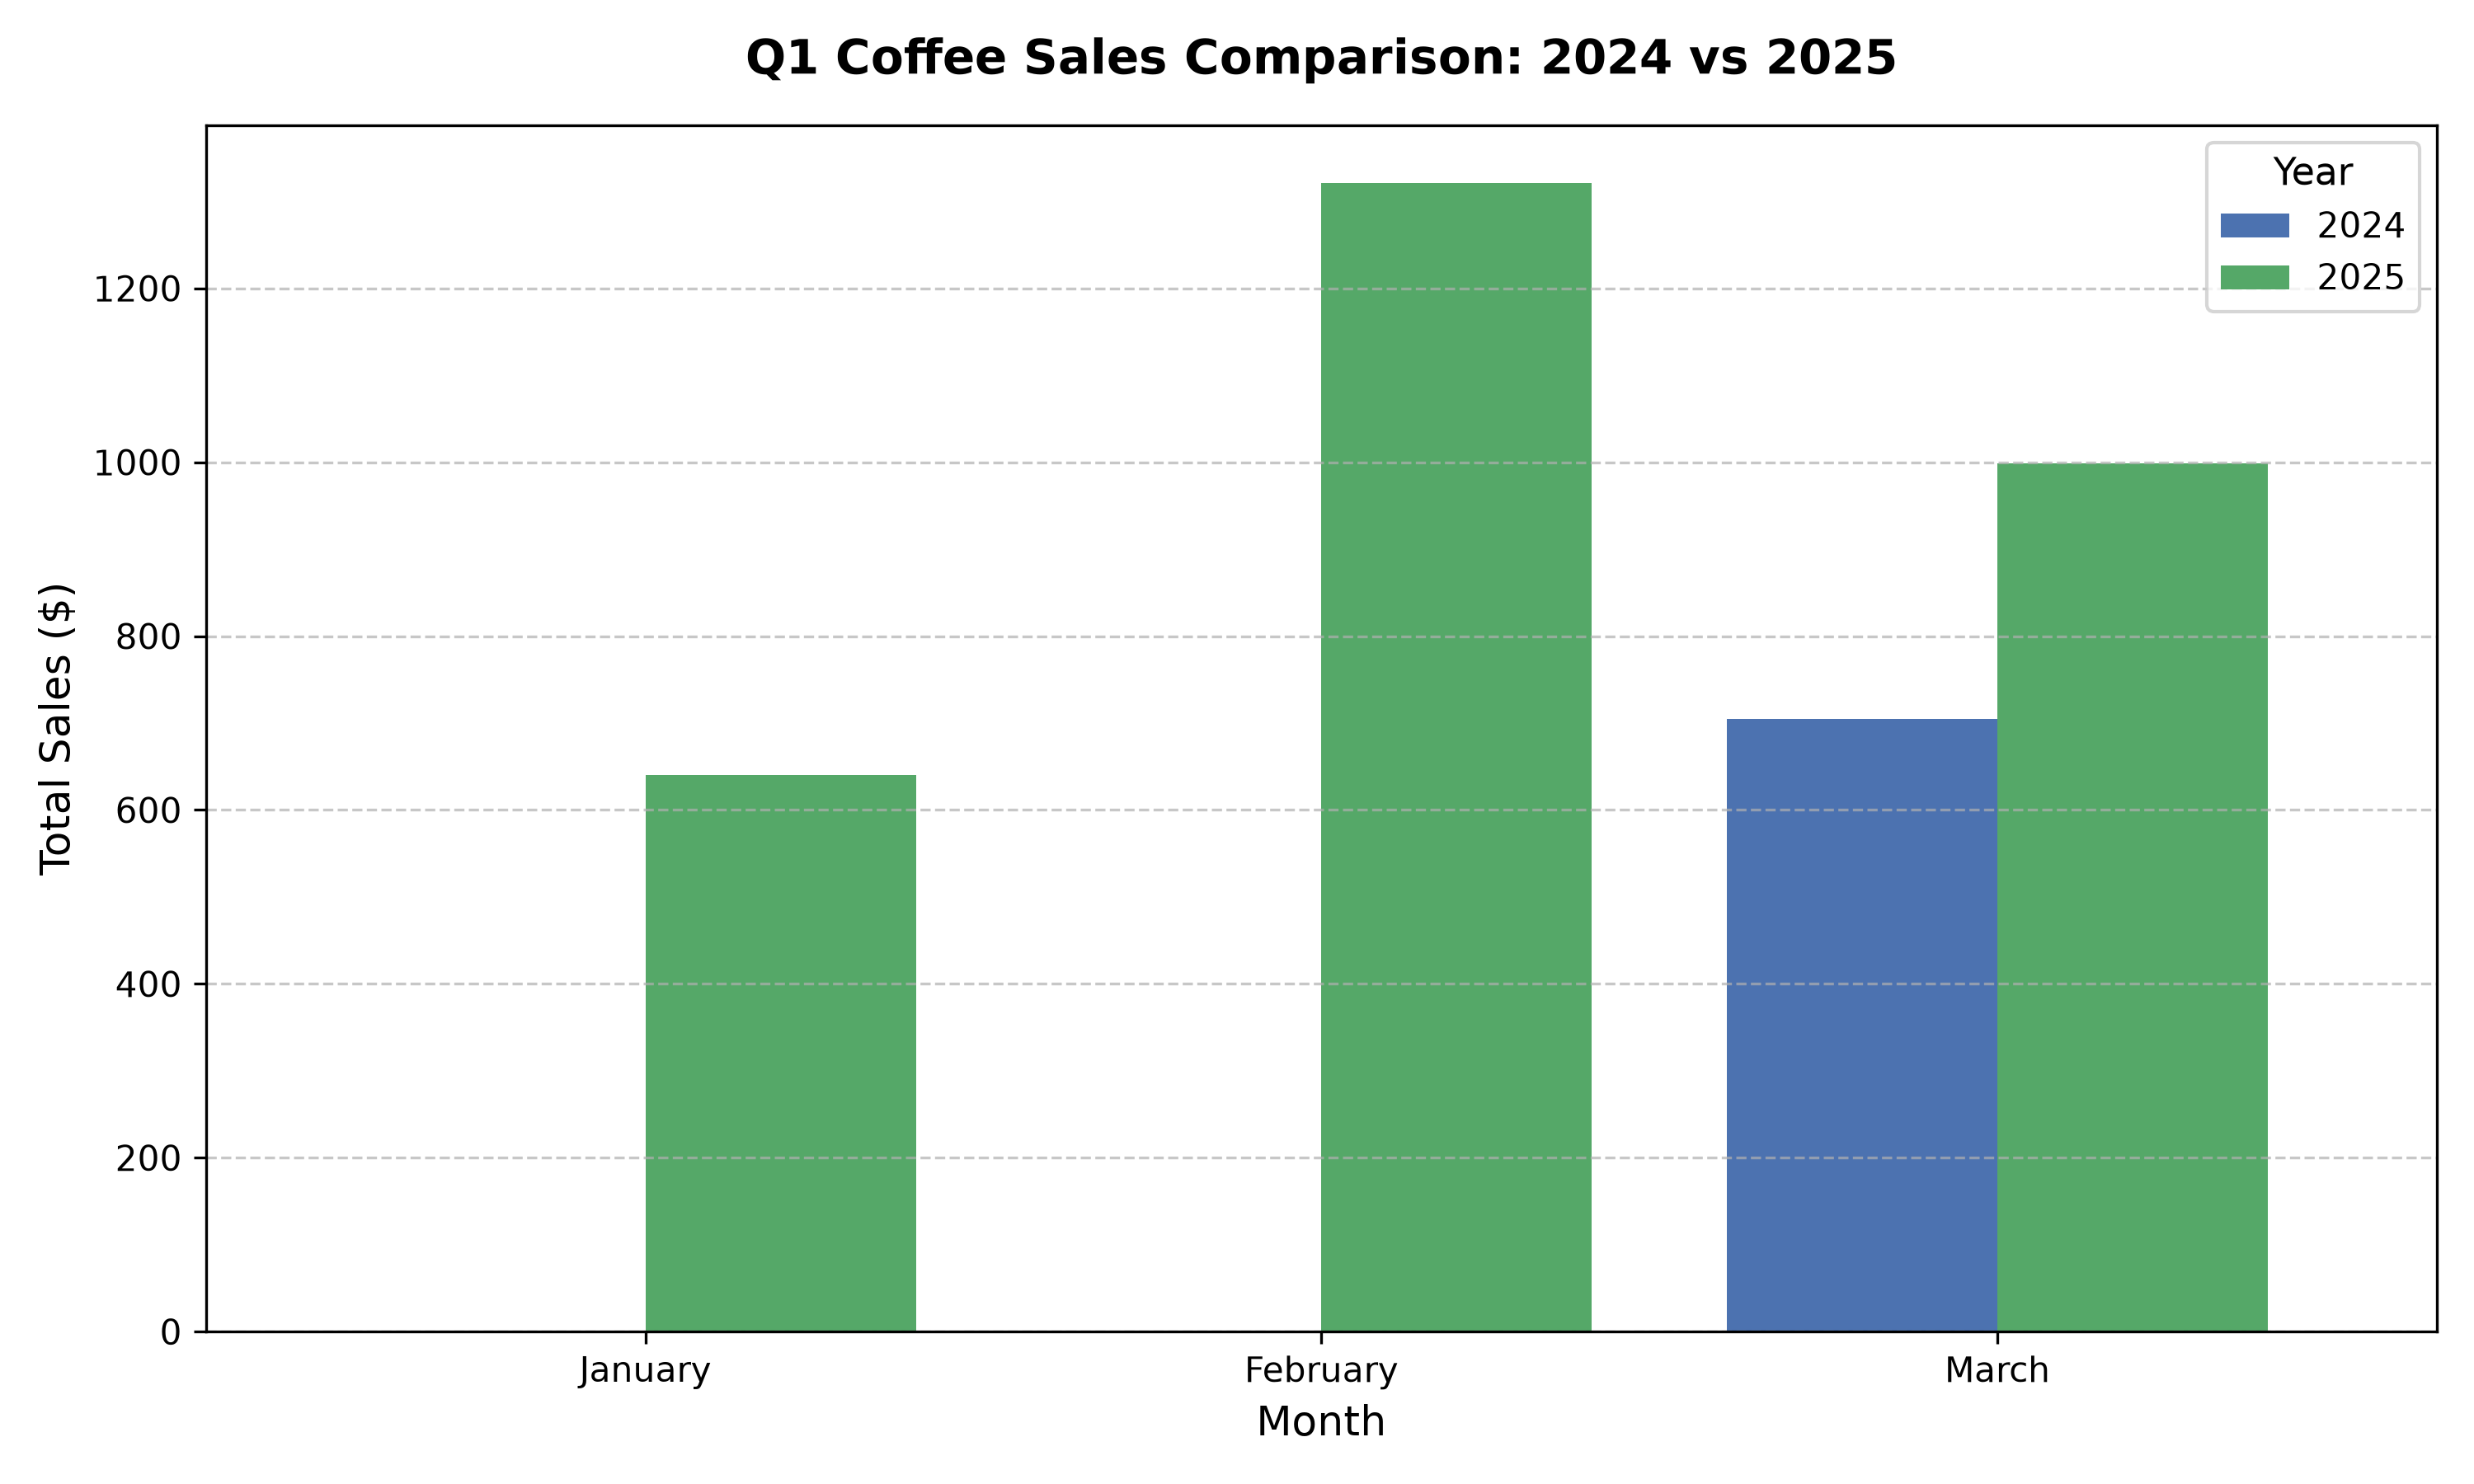


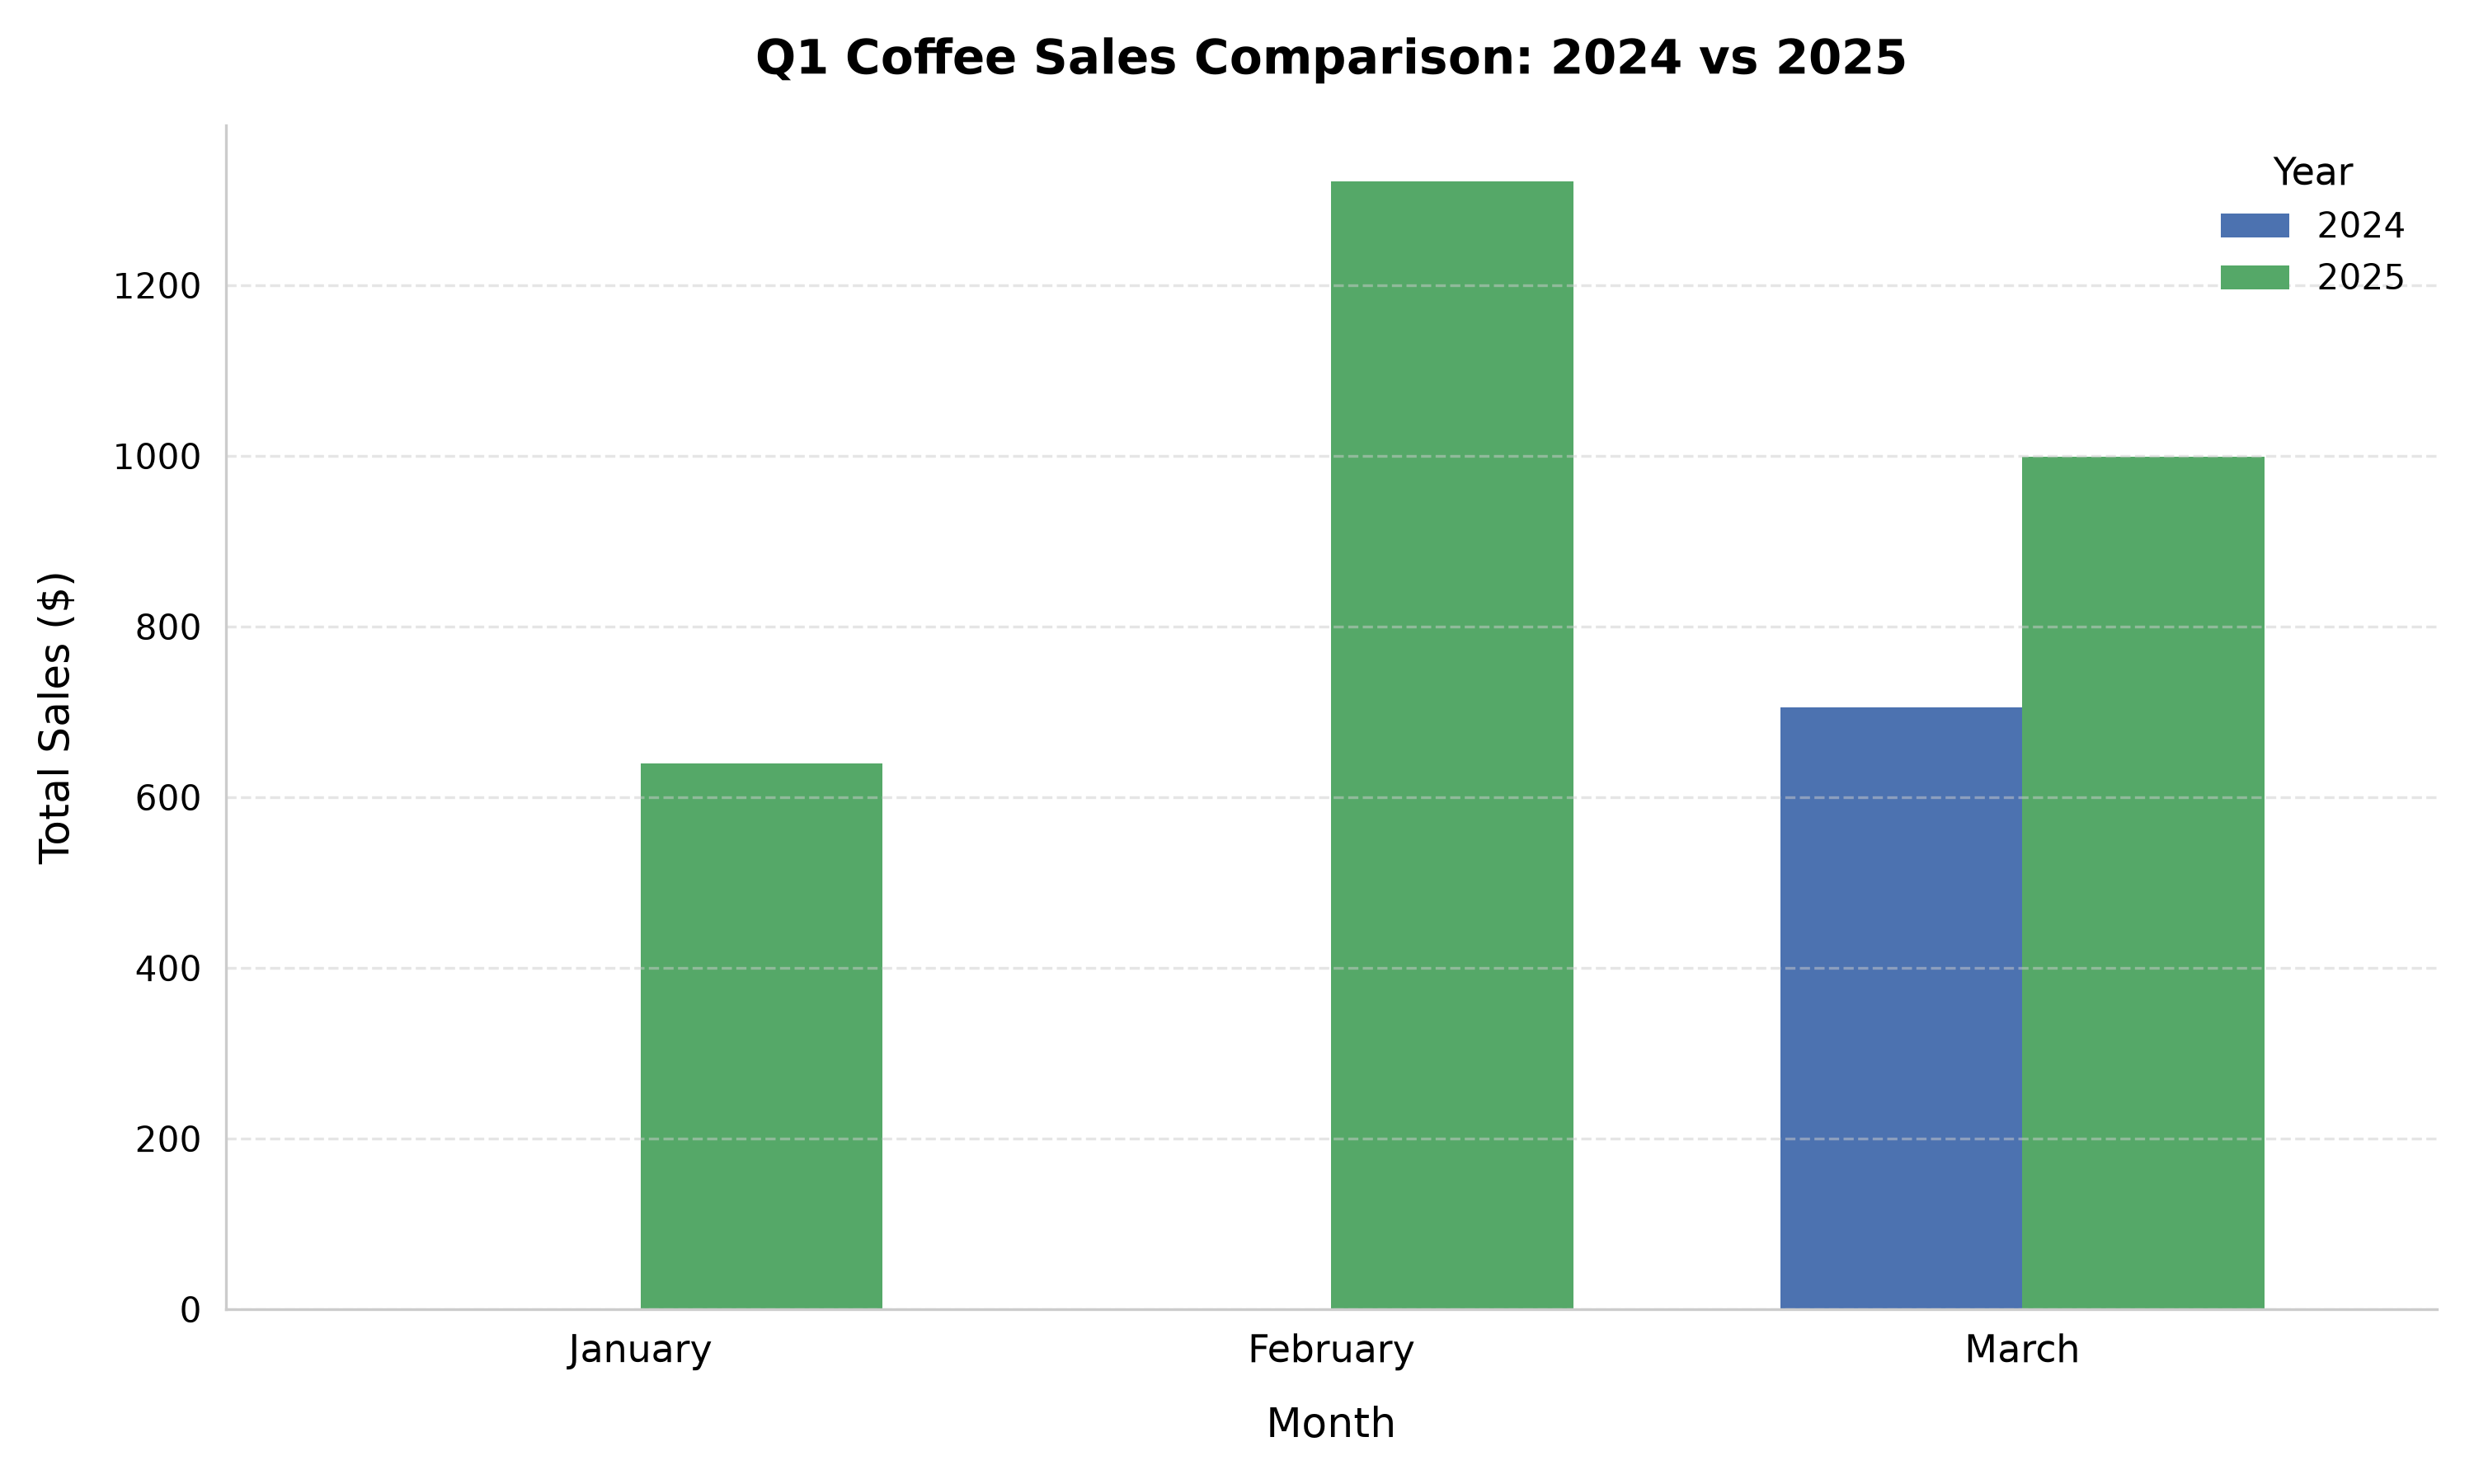

In [55]:
user_instructions = "Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv."  # write your instruction here
generation_model = "gemini-3.1-flash-lite"
reflection_model = "gemini-3.1-flash-lite"
image_basename = "coffe_sales"

code_v1, chart_v1, feedback, code_v2, chart_v2 = run_workflow(
    dataset_path="coffee_sales.csv",
    user_instruction=user_instructions,
    generation_model=generation_model,
    reflection_model=reflection_model,
    image_baseline=image_basename 
)
